# Video Games Sales 

In [117]:
# Importación de Librerias
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split

---

In [118]:
df = pd.read_csv('../data/raw/vgsales.csv')
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [119]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  str    
 5   Publisher     16540 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 2.1 MB


In [120]:
df.isnull().sum()

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [121]:
df_clean = df.dropna().copy()
df_clean.info()
display(df_clean.isnull().sum())

<class 'pandas.DataFrame'>
Index: 16291 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16291 non-null  int64  
 1   Name          16291 non-null  str    
 2   Platform      16291 non-null  str    
 3   Year          16291 non-null  float64
 4   Genre         16291 non-null  str    
 5   Publisher     16291 non-null  str    
 6   NA_Sales      16291 non-null  float64
 7   EU_Sales      16291 non-null  float64
 8   JP_Sales      16291 non-null  float64
 9   Other_Sales   16291 non-null  float64
 10  Global_Sales  16291 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 2.2 MB


Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

In [122]:
df_clean['Year'] = df_clean['Year'].astype(int)

In [123]:
df_clean.info()
display(df_clean.head())


<class 'pandas.DataFrame'>
Index: 16291 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16291 non-null  int64  
 1   Name          16291 non-null  str    
 2   Platform      16291 non-null  str    
 3   Year          16291 non-null  int64  
 4   Genre         16291 non-null  str    
 5   Publisher     16291 non-null  str    
 6   NA_Sales      16291 non-null  float64
 7   EU_Sales      16291 non-null  float64
 8   JP_Sales      16291 non-null  float64
 9   Other_Sales   16291 non-null  float64
 10  Global_Sales  16291 non-null  float64
dtypes: float64(5), int64(2), str(4)
memory usage: 2.2 MB


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [124]:
print(df_clean['Year'].min())
print(df_clean['Year'].max())

1980
2020


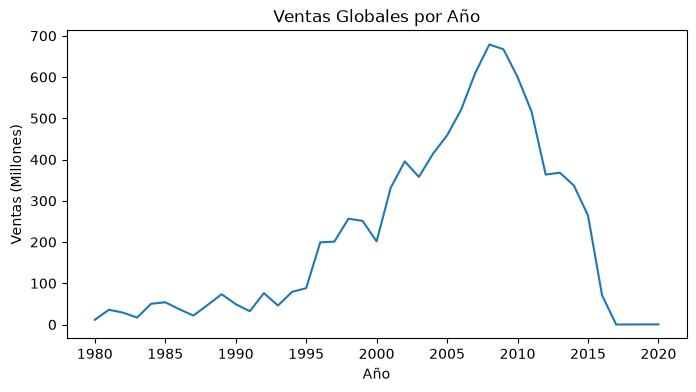

In [125]:
ventas_por_anio = df_clean.groupby('Year')['Global_Sales'].sum()

ventas_por_anio.plot(kind='line', figsize=(8, 4), title='Ventas Globales por Año')
plt.xlabel('Año')
plt.ylabel('Ventas (Millones)')
plt.show()

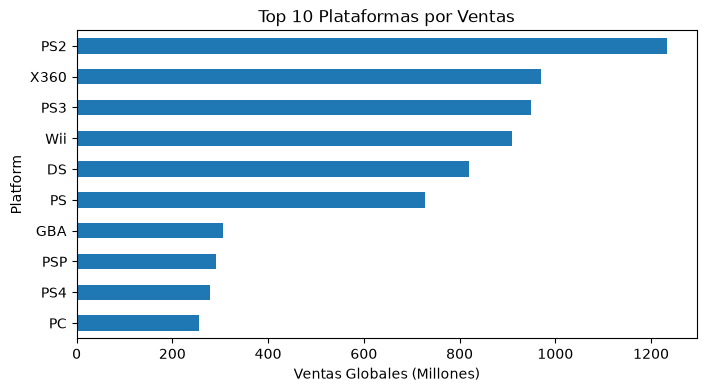

In [126]:
top_plataformas = df_clean.groupby('Platform')['Global_Sales'].sum().sort_values().tail(10)

top_plataformas.plot(kind='barh', figsize=(8, 4), title='Top 10 Plataformas por Ventas')
plt.xlabel('Ventas Globales (Millones)')
plt.show()

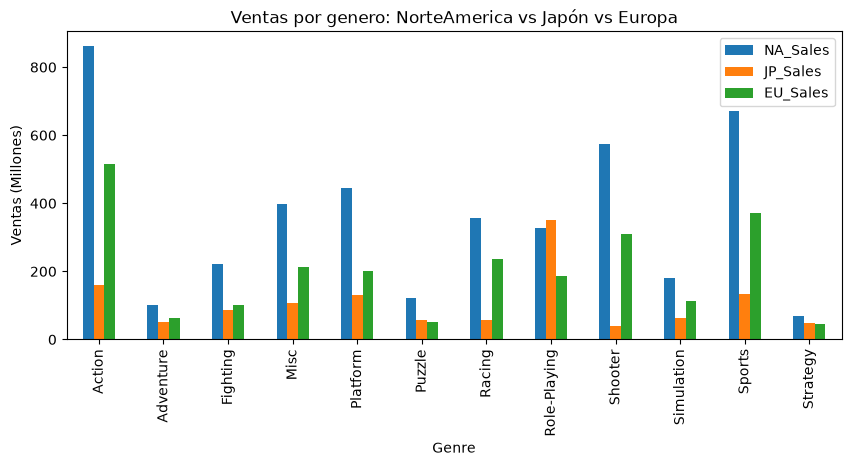

In [127]:
ventas_genero = df_clean.groupby('Genre')[['NA_Sales', 'JP_Sales', 'EU_Sales']].sum()

ventas_genero.plot(kind='bar', figsize=(10, 4), title='Ventas por genero: NorteAmerica vs Japón vs Europa')
plt.ylabel('Ventas (Millones)')
plt.show()

---

---

In [128]:
df_clean['Exito'] = (df_clean['Global_Sales'] >= 1.0).astype(int) # Si vendio más de 1M, exito

df_clean

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Exito
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,1
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,1
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,1
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,1
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,1
...,...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01,0
16594,16597,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01,0
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01,0
16596,16599,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01,0


In [130]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

X = df_clean[['Platform', 'Year', 'Genre', 'Publisher']]
y = df_clean['Exito']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


X_train = pd.get_dummies(X_train) 
X_test = pd.get_dummies(X_test)


X_test = X_test.reindex(columns=X_train.columns, fill_value=0) # Si falta alguna columna, la agrega rellena de puro 0

,precision,recall,f1-score,support
No exitoso,0.887874,0.990165,0.936234,2847.0
Exitoso,0.666667,0.135922,0.225806,412.0


Accuracy: 0.88


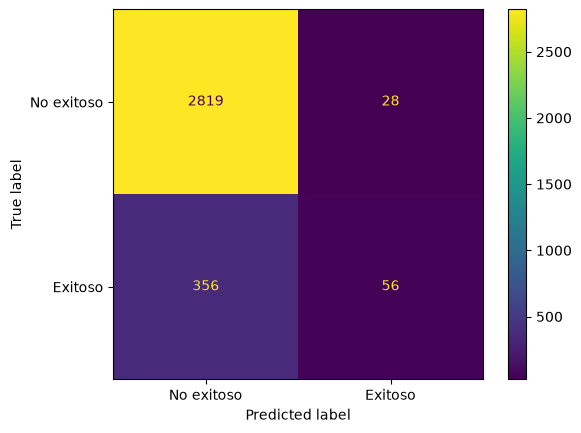

In [ ]:
modelo = DecisionTreeClassifier(max_depth=5, random_state=42)
modelo.fit(X_train, y_train)


predicciones = modelo.predict(X_test)



reporte = classification_report(
    y_test, predicciones,
    target_names=['No exitoso', 'Exitoso'],
    output_dict=True
)

display(pd.DataFrame(reporte).T.loc[
    ['No exitoso', 'Exitoso'],
    ['precision', 'recall', 'f1-score']
])

print(f"Accuracy: {reporte['accuracy']:.2f}")



ConfusionMatrixDisplay.from_predictions(
    y_test, predicciones,
    display_labels=['No exitoso', 'Exitoso']
)
plt.show()

,precision,recall,f1-score
No exitoso,0.914731,0.885494,0.899875
Exitoso,0.351889,0.429612,0.386885


Accuracy: 0.83


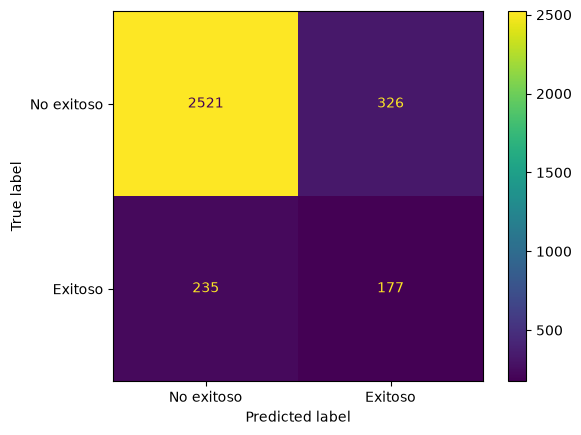

In [135]:
# Segundo modelo: árbol de decisión con clases balanceadas

modelo_balanceado = DecisionTreeClassifier(
    max_depth=5,
    random_state=42,
    class_weight='balanced'
)

modelo_balanceado.fit(X_train, y_train)

predicciones_balanceadas = modelo_balanceado.predict(X_test)



reporte = classification_report(
    y_test, predicciones_balanceadas,
    target_names=['No exitoso', 'Exitoso'],
    output_dict=True
)

display(pd.DataFrame(reporte).T.loc[
    ['No exitoso', 'Exitoso'],
    ['precision', 'recall', 'f1-score']
])

print(f"Accuracy: {reporte['accuracy']:.2f}")



ConfusionMatrixDisplay.from_predictions(
    y_test, predicciones_balanceadas,
    display_labels=['No exitoso', 'Exitoso']
)

plt.show()

Modelo 1: Árbol de decisión original


- Accuracy (0.88): Clasificó correctamente el 88% de los videojuegos.

- Precision: Acertó el 89% de sus predicciones de videojuegos no exitosos y el 67% de los exitosos.

- Recall: Identificó el 99% de los no exitosos, pero solamente el 14% de los exitosos.

- F1-score: Fue de 0.94 para no exitosos y 0.23 para exitosos, mostrando dificultades para detectar esta última clase.

Modelo 2: Árbol de decisión balanceado

- Accuracy (0.83): Clasificó correctamente el 83% de los videojuegos.

- Precision: Acertó el 91% de sus predicciones de no exitosos y el 35% de los exitosos.

- Recall: Identificó el 89% de los no exitosos y el 43% de los exitosos.

- F1-score: Fue de 0.90 para no exitosos y 0.39 para exitosos, mejorando la detección de la clase que nos interesa.

Conclusión: El primer modelo obtuvo mayor exactitud, pero el segundo identifico más videojuegos exitosos. Pero cometió más errores al hacerlo, resultó este segundo modelo ser el más adecuado para el objetivo de detectar éxitos comerciales... aunque aún dejando bastante margen de error.